In [5]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import mean_absolute_error, r2_score 
from sklearn.ensemble import RandomForestRegressor
import numpy as np
import joblib
import matplotlib.pyplot as plt


df = pd.read_csv("fifa_playerss.csv")

print(df.head())

           name                       full_name birth_date  age  height_cm  \
0      L. Messi  Lionel Andrés Messi Cuccittini  6/24/1987   31     170.18   
1    C. Eriksen    Christian  Dannemann Eriksen  2/14/1992   27     154.94   
2      P. Pogba                      Paul Pogba  3/15/1993   25     190.50   
3    L. Insigne                 Lorenzo Insigne   6/4/1991   27     162.56   
4  K. Koulibaly               Kalidou Koulibaly  6/20/1991   27     187.96   

   weight_kgs  positions nationality  overall_rating  potential  ...  \
0        72.1   CF,RW,ST   Argentina              94         94  ...   
1        76.2  CAM,RM,CM     Denmark              88         89  ...   
2        83.9     CM,CAM      France              88         91  ...   
3        59.0      LW,ST       Italy              88         88  ...   
4        88.9         CB     Senegal              88         91  ...   

   long_shots  aggression interceptions  positioning  vision  penalties  \
0          94          

In [2]:
features = ['age', 'height_cm', 'weight_kgs', 'positions', 'overall_rating', 'weak_foot(1-5)', 'skill_moves(1-5)', 'crossing', 'finishing', 'heading_accuracy', 'short_passing', 'volleys', 'dribbling', 'curve', 'freekick_accuracy', 'ball_control', 'acceleration', 'sprint_speed', 'agility', 'shot_power', 'penalties', 'marking']

data = df[features + ['value_euro']].dropna()

y = data['value_euro']

X = data[features]

X_encoded = pd.get_dummies(X, columns=['positions'], drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size= 0.2, random_state= 42)

model = DecisionTreeRegressor(random_state= 42)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"El modelo entiende el {r2 * 100:.2f}% de los precios.")
print(f"De media, se equivoca en: {mae:,.2f} Euros por jugador.")

El modelo entiende el 95.23% de los precios.
De media, se equivoca en: 256,525.42 Euros por jugador.


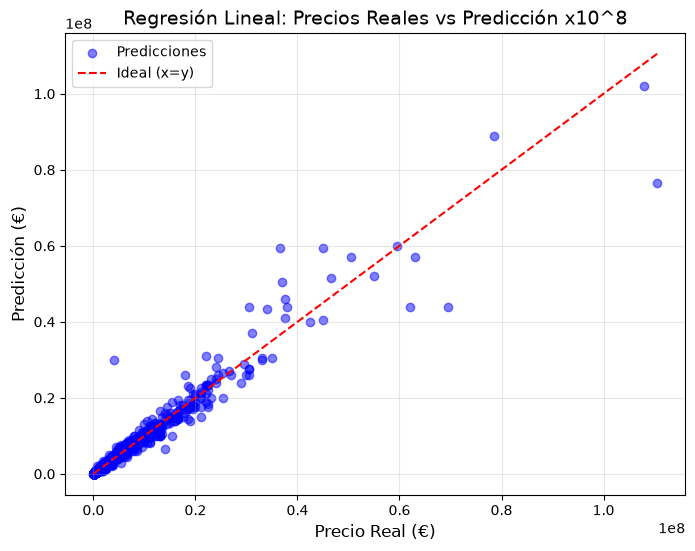

In [4]:
plt.figure(figsize=(8, 6))

# Dibujar los puntos: Eje X = Real, Eje Y = Predicción
plt.scatter(y_test, y_pred, alpha=0.5, color='blue', label='Predicciones')

# Línea diagonal de referencia (Predicción perfecta)
max_val = max(y_test.max(), y_pred.max())
min_val = min(y_test.min(), y_pred.min())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='Ideal (x=y)')

plt.title("Regresión Lineal: Precios Reales vs Predicción x10^8", fontsize=14)
plt.xlabel("Precio Real (€)", fontsize=12)
plt.ylabel("Predicción (€)", fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)

plt.savefig("real_vs_predicted.png", dpi=300, bbox_inches='tight')
plt.show()
plt.close()